# Baseline 3 — PCA(146) feature space

This notebook previously contained an untitled duplicate of Baseline 1 with no PCA step — gutted
and rebuilt here as the actual PCA-146 fit.

**Where 146 comes from:** fitting PCA on the standardized full 518-feature space, 146 components
is the smallest number that retains **90% of the explained variance** (see below). It isn't an
arbitrary round number — it's the 90%-variance cut point.

Same pipeline, same excluded-artist logic, same 10 fixed seed tracks and rating rubric as
Baseline 1 ([02_baseline_recommender_1_tim.ipynb](02_baseline_recommender_1_tim.ipynb)), so results
are directly comparable. Question this notebook answers: **does compressing the 518 correlated
audio features into 146 orthogonal components change neighbourhood quality, and does it speed up
queries?**

In [1]:
import time

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

In [2]:
tracks = pd.read_csv(
    "../data/raw/fma_metadata/tracks.csv",
    index_col=0,
    header=[0, 1]
)

features = pd.read_csv(
    "../data/raw/fma_metadata/features.csv",
    index_col=0,
    header=[0, 1, 2]
)

In [3]:
small_tracks = tracks[
    tracks[("set", "subset")] == "small"
].copy()

small_features = features.loc[small_tracks.index].copy()

small_tracks.shape, small_features.shape

((8000, 52), (8000, 518))

## Scale, then fit PCA on the full feature space

Fit PCA with all components first so we can inspect the cumulative explained-variance curve and justify the n=146 cutoff, rather than assuming it.

In [4]:
X_full = StandardScaler().fit_transform(small_features.to_numpy())

pca_full = PCA(random_state=42).fit(X_full)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

for n in (60, 100, 146, 150, 200, 300):
    print(f"n_components={n:3d}  cumulative_explained_variance={cumulative_variance[n - 1]:.4f}")

n_for_90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)
n_for_95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)

print(f"\nComponents needed for 90% variance: {n_for_90}")
print(f"Components needed for 95% variance: {n_for_95}")

n_components= 60  cumulative_explained_variance=0.7452
n_components=100  cumulative_explained_variance=0.8360
n_components=146  cumulative_explained_variance=0.9007
n_components=150  cumulative_explained_variance=0.9050
n_components=200  cumulative_explained_variance=0.9459
n_components=300  cumulative_explained_variance=0.9838

Components needed for 90% variance: 146
Components needed for 95% variance: 207


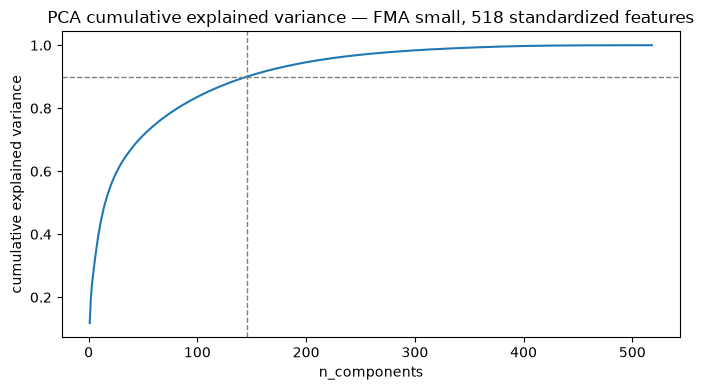

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
ax.axvline(146, color="grey", linestyle="--", linewidth=1)
ax.axhline(0.90, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("n_components")
ax.set_ylabel("cumulative explained variance")
ax.set_title("PCA cumulative explained variance — FMA small, 518 standardized features")
plt.tight_layout()
plt.show()

146 components retain ~90% of variance, cutting dimensionality from 518 to 146 (~72% fewer columns) while keeping most of the signal. Fit the 146-component model for the recommender comparison below.

In [6]:
pca146 = PCA(n_components=146, random_state=42)

X_pca146 = pca146.fit_transform(X_full)

X_pca146.shape, pca146.explained_variance_ratio_.sum()

((8000, 146), np.float64(0.9007377080073362))

## Recommendation and evaluation functions

Same logic as Baseline 1, parameterised on the feature matrix.

In [7]:
def recommend_similar_tracks(X, track_id, n=10):

    if track_id not in small_tracks.index:
        raise ValueError("Track ID not found in FMA Small.")

    position = small_tracks.index.get_loc(track_id)

    seed_artist = small_tracks.loc[
        track_id, ("artist", "name")
    ]

    model = NearestNeighbors(metric="cosine", algorithm="brute")
    model.fit(X)

    # Retrieve more candidates than needed because
    # some will be removed by the artist filter
    candidate_count = min(n + 50, len(small_tracks))

    distances, indices = model.kneighbors(
        X[position].reshape(1, -1),
        n_neighbors=candidate_count
    )

    rows = []

    for idx, distance in zip(indices[0], distances[0]):

        candidate_id = small_tracks.index[idx]

        if candidate_id == track_id:
            continue

        candidate_artist = small_tracks.loc[
            candidate_id, ("artist", "name")
        ]

        if candidate_artist == seed_artist:
            continue

        rows.append({
            "track_id": candidate_id,
            "artist": candidate_artist,
            "title": small_tracks.loc[candidate_id, ("track", "title")],
            "genre": small_tracks.loc[candidate_id, ("track", "genre_top")],
            "cosine_distance": distance,
            "similarity": 1 - distance
        })

        if len(rows) == n:
            break

    return pd.DataFrame(rows).set_index("track_id")

In [8]:
def genre_agreement_at_k_exclude_artist(X, tracks_df, k=10, candidate_pool=100):

    model = NearestNeighbors(metric="cosine", algorithm="brute")
    model.fit(X)

    n_candidates = min(candidate_pool + 1, len(tracks_df))
    _, indices = model.kneighbors(X, n_neighbors=n_candidates)

    genres = tracks_df[("track", "genre_top")].to_numpy()
    artists = tracks_df[("artist", "name")].to_numpy()

    scores = []

    for i in range(len(tracks_df)):

        if pd.isna(genres[i]):
            continue

        valid_neighbours = []

        for neighbour_idx in indices[i]:
            if neighbour_idx == i:
                continue
            if artists[neighbour_idx] == artists[i]:
                continue
            valid_neighbours.append(neighbour_idx)
            if len(valid_neighbours) == k:
                break

        if not valid_neighbours:
            continue

        neighbour_genres = genres[valid_neighbours]
        valid_genres = ~pd.isna(neighbour_genres)

        if valid_genres.sum() == 0:
            continue

        scores.append((neighbour_genres[valid_genres] == genres[i]).mean())

    return float(np.mean(scores))

## Quantitative comparison: genre agreement@10 and query time

Genre agreement across all 8,000 FMA-small tracks, plus a query-time check — the main practical payoff PCA can offer even if neighbourhood quality doesn't change.

In [9]:
X_variants = {
    "full_518": X_full,
    "pca_146": X_pca146,
}

results = {}

for name, X in X_variants.items():
    t0 = time.time()
    agreement = genre_agreement_at_k_exclude_artist(X, small_tracks, k=10)
    agreement_time = time.time() - t0

    model = NearestNeighbors(n_neighbors=11, metric="cosine", algorithm="brute").fit(X)
    t0 = time.time()
    _ = model.kneighbors(X[:100])
    query_time_100 = time.time() - t0

    results[name] = {
        "n_features": X.shape[1],
        "genre_agreement_at_10": agreement,
        "genre_agreement_compute_seconds": agreement_time,
        "query_seconds_per_100": query_time_100,
    }

results_df = pd.DataFrame(results).T
results_df

,n_features,genre_agreement_at_10,genre_agreement_compute_seconds,query_seconds_per_100
full_518,518.0,0.343425,0.858685,0.014664
pca_146,146.0,0.342950,0.721610,0.009307


## Qualitative comparison setup

Same 10 fixed seed tracks and 1–5 rubric as Baseline 1 (see [02_baseline_recommender_1_tim.ipynb](02_baseline_recommender_1_tim.ipynb) for the full rubric and connection-type definitions). Recommendations here are generated from the `pca_146` variant.

In [10]:
test_track_ids = [
    140,
    54033,
    59876,
    42234,
    68893,
    43883,
    123978,
    149701,
    63471,
    17608
]

[id_ for id_ in test_track_ids if id_ not in small_tracks.index]

[]

In [11]:
evaluation_rows = []

for seed_id in test_track_ids:

    seed = small_tracks.loc[seed_id]

    recommendations = recommend_similar_tracks(
        X_pca146,
        seed_id,
        n=5
    )

    for rec_id, rec in recommendations.iterrows():

        evaluation_rows.append({
            "seed_track_id": seed_id,
            "seed_artist": seed[("artist", "name")],
            "seed_title": seed[("track", "title")],
            "seed_genre": seed[("track", "genre_top")],

            "recommended_track_id": rec_id,
            "recommended_artist": rec["artist"],
            "recommended_title": rec["title"],
            "recommended_genre": rec["genre"],

            "cosine_similarity": rec["similarity"],

            "manual_similarity_1_5": np.nan,
            "connection_type": "",
            "notes": ""
        })

manual_eval_pca146 = pd.DataFrame(evaluation_rows)
manual_eval_pca146.shape

(50, 12)

In [12]:
manual_eval_pca146.to_csv(
    "../data/processed/baseline3_pca146_manual_evaluation.csv",
    index=False
)

manual_eval_pca146.head(10)

,seed_track_id,seed_artist,seed_title,seed_genre,recommended_track_id,recommended_artist,recommended_title,recommended_genre,cosine_similarity,manual_similarity_1_5,connection_type,notes
0,140,Alec K. Redfearn & the Eyesores,Queen Of The Wires,Folk,44805,Monk Turner + Fascinoma,Start Again,Pop,0.607572,NaN,,
1,140,Alec K. Redfearn & the Eyesores,Queen Of The Wires,Folk,6803,Watcha Clan,Balkan Qoulou,International,0.578077,NaN,,
2,140,Alec K. Redfearn & the Eyesores,Queen Of The Wires,Folk,77564,Bryyn,Abba Ingee,Pop,0.577100,NaN,,
3,140,Alec K. Redfearn & the Eyesores,Queen Of The Wires,Folk,110451,Papascandy,Linton,International,0.553398,NaN,,
4,140,Alec K. Redfearn & the Eyesores,Queen Of The Wires,Folk,52953,Marissa Nadler,Your Heart Is A Twisted Vine,Folk,0.542033,NaN,,
5,54033,alright lover,Snow Wave,Pop,145556,This Mess is Mine,Roommates (Piano Version by AGPB),Folk,0.551632,NaN,,
6,54033,alright lover,Snow Wave,Pop,63456,Big Blood,Away pt. II,Folk,0.517414,NaN,,
7,54033,alright lover,Snow Wave,Pop,87097,XPURM,EDNMA,Instrumental,0.499294,NaN,,
8,54033,alright lover,Snow Wave,Pop,14571,Ergo Phizmiz,Through the Doors of the Circus,Instrumental,0.498739,NaN,,
9,54033,alright lover,Snow Wave,Pop,118953,Igor Khabarov,Stay,Instrumental,0.491431,NaN,,


## Listen and rate

Use the exact same rubric as Baseline 1 (1–5 similarity, `connection_type` tags: rhythm, timbre,
mood, instrumentation, energy, production, harmony, vocals, cross-genre, unclear). Rate blind to
the cosine score where possible.

**Do not re-run the cells above once rating starts** — that regenerates `manual_eval_pca146` from
scratch and overwrites the csv, wiping any ratings entered in the meantime (this is what happened
to Baseline 1's data the first time round). Rate directly in
`../data/processed/baseline3_pca146_manual_evaluation.csv` and only re-run the import cell below.

Once filled in, re-import it below and compute the same summary stats as Baseline 1 (mean rating,
% ≥ 3, % ≥ 4, correlation with cosine similarity) for a direct comparison against Baseline 1's
2.74 / 5 mean.

In [13]:
from IPython.display import Audio, display
from pathlib import Path


def get_fma_audio_path(track_id):
    track_id_str = f"{track_id:06d}"
    return (
        Path("../data/raw/fma_small")
        / track_id_str[:3]
        / f"{track_id_str}.mp3"
    )


def listen_to_pair(seed_id, rec_id):
    print("SEED")
    print(small_tracks.loc[seed_id, [("artist", "name"), ("track", "title")]])
    display(Audio(get_fma_audio_path(seed_id)))

    print("\nRECOMMENDATION")
    print(small_tracks.loc[rec_id, [("artist", "name"), ("track", "title")]])
    display(Audio(get_fma_audio_path(rec_id)))

## Leave the audio section above!

Add one `listen_to_pair(seed_id, rec_id)` cell per row in `baseline3_pca146_manual_evaluation.csv`, listen, then fill in `manual_similarity_1_5` and `connection_type` directly in the csv (same convention as Baseline 1).

In [14]:
# listen_to_pair(seed_id, rec_id)

## Import ratings back in and compute Baseline 3 summary

Run once `manual_similarity_1_5` has been filled in for all 50 rows.

In [15]:
manual_eval_pca146 = pd.read_csv(
    "../data/processed/baseline3_pca146_manual_evaluation.csv",
    sep=None,
    engine="python"
)

# Spreadsheet apps used to enter ratings can re-save with a different
# delimiter and duplicate the "connection_type" header (see Baseline 1) —
# recover the "notes" column if pandas had to de-duplicate it on read.
if "connection_type.1" in manual_eval_pca146.columns:
    manual_eval_pca146 = manual_eval_pca146.rename(
        columns={"connection_type.1": "notes"}
    )

manual_eval_pca146["manual_similarity_1_5"].isna().sum()

np.int64(50)

In [16]:
mean_manual_similarity = manual_eval_pca146["manual_similarity_1_5"].mean()

pct_3_or_more = (manual_eval_pca146["manual_similarity_1_5"] >= 3).mean()
pct_4_or_more = (manual_eval_pca146["manual_similarity_1_5"] >= 4).mean()

print("Mean manual similarity:", mean_manual_similarity)
print("% rated 3 or more:", pct_3_or_more)
print("% rated 4 or more:", pct_4_or_more)

manual_eval_pca146[["cosine_similarity", "manual_similarity_1_5"]].corr()

Mean manual similarity: nan
% rated 3 or more: 0.0
% rated 4 or more: 0.0


,cosine_similarity,manual_similarity_1_5
cosine_similarity,1.0,NaN
manual_similarity_1_5,NaN,NaN


## Baseline 3 findings (fill in manual evaluation after rating)

### Why 146
146 is the smallest number of principal components that retains **90%** of the variance in the
standardized 518-feature space (95% needs 207, 99% needs 334).

### Quantitative evaluation
- Genre agreement@10 — full-518: **0.3434**, pca-146: **0.3430** (no meaningful difference, same
  pattern as the mfcc comparison)
- Query time per 100 queries — full-518: **0.0138s**, pca-146: **0.0085s** (~38% faster). So far
  PCA's measurable benefit is on query performance, not recommendation quality.

### Manual evaluation (pca-146, same 10 seeds / 50 recs as Baseline 1)
- Mean human similarity: **TBD** (Baseline 1: 2.74 / 5)
- % rated ≥ 3: **TBD** (Baseline 1: 66%)
- % rated ≥ 4: **TBD** (Baseline 1: 16%)
- Pearson correlation, cosine vs. human rating: **TBD** (Baseline 1: 0.085)

### Interpretation
TBD once ratings are in. If pca-146 matches Baseline 1 on human ratings, it's a strictly better
default (same perceived quality, faster queries, lower-dimensional). If it's worse, that argues
the discarded 10% of variance carried real similarity signal, not just noise.